# Text Classification on Spam Detection

## Task 0: Define Directory Path and Library Imports

In [54]:
# Import library
import re
import string
import nltk
import pandas as pd
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import accuracy_score, classification_report, f1_score, recall_score
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import VotingClassifier

# Download resource for tokenization and lemmatization
nltk.download('punkt')
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("averaged_perceptron_tagger")

# This is to let the rows be shown in rows without line wrapping
pd.set_option("display.expand_frame_repr", False)

# Define dataset directory
dataset_path = "Part_B_Data/SMSSpamCollection.txt"

[nltk_data] Downloading package punkt to
[nltk_data]     /Users/limbengrhui/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/limbengrhui/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/limbengrhui/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/limbengrhui/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /Users/limbengrhui/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!


## Task 1: Data Loading

### 1.1 Convert dataset from .txt to Pandas DataFrame

In [3]:
# Convert to data frames
dataset = pd.read_csv(dataset_path, sep="\t", header=None, names=["label", "message"])
print(dataset.head())

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


## Task 2: Initial Exploratory Data Analysis

### 2.1 Target variable distribution

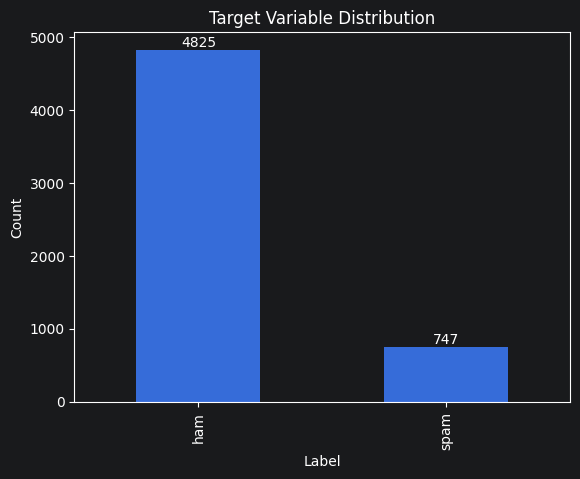

In [4]:
# Count the number of labels and store it as a bar chart
target_var_graph = dataset["label"].value_counts()
target_var_graph = target_var_graph.plot(kind="bar")

# Initialize the details of the chart
plt.title("Target Variable Distribution")
plt.xlabel("Label")
plt.ylabel("Count")

# Add value labels on top of each bar
for bar in target_var_graph.patches:
    target_var_graph.annotate(
        str(bar.get_height()),
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )

# Show the chart
plt.show()

### 2.2 Character count and sentence count distribution

  label                                            message  character_count  sentence_count
0   ham  Go until jurong point, crazy.. Available only ...              111               2
1   ham                      Ok lar... Joking wif u oni...               29               2
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...              155               2
3   ham  U dun say so early hor... U c already then say...               49               1
4   ham  Nah I don't think he goes to usf, he lives aro...               61               1


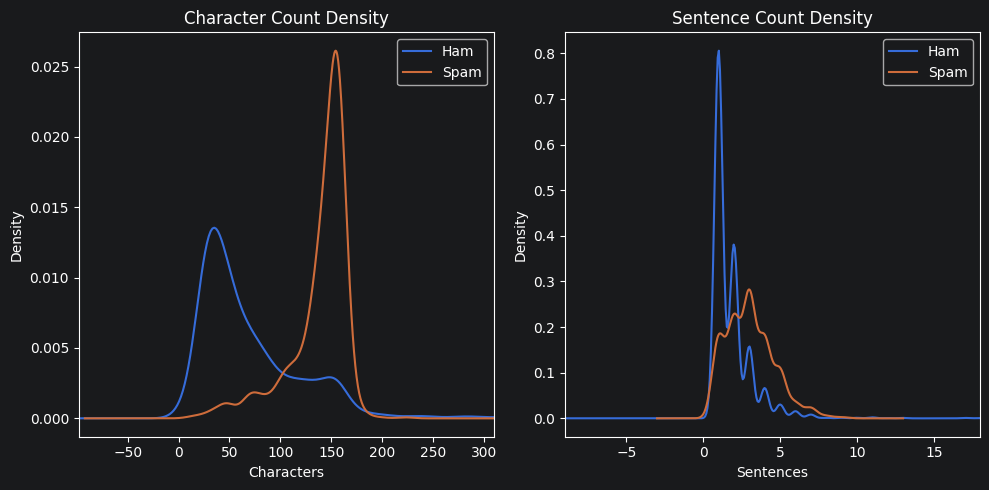

In [5]:
# First, calculate the character count and the sentence count
dataset["character_count"] = dataset["message"].apply(len)
dataset["sentence_count"] = dataset["message"].apply(
    lambda text: len(nltk.sent_tokenize(text))
)

# Display the dataset to show successful modification
print(dataset.head())

# Divide the data based on ham and spam
ham = dataset[dataset["label"] == "ham"]
spam = dataset[dataset["label"] == "spam"]

# Set up the figure size
plt.figure(figsize=(10,5))

# Plot for character counts
plt.subplot(1, 2, 1)
ham["character_count"].plot(kind="kde", label="Ham")
spam["character_count"].plot(kind="kde", label="Spam")
plt.title("Character Count Density")
plt.xlabel("Characters")
plt.xlim(dataset["character_count"].min() - 100, dataset["character_count"].max() - 600)    # This is to limit the x-axis to the data range
plt.legend()

# Plot for sentence counts
plt.subplot(1, 2, 2)
ham["sentence_count"].plot(kind="kde", label="Ham")
spam["sentence_count"].plot(kind="kde", label="Spam")
plt.title("Sentence Count Density")
plt.xlabel("Sentences")
plt.xlim(dataset["sentence_count"].min() - 10, dataset["sentence_count"].max() - 20)      # This is to limit the x-axis to the data range
plt.legend()

# Display the plots
plt.tight_layout()
plt.show()

### 2.3 Missing value distribution

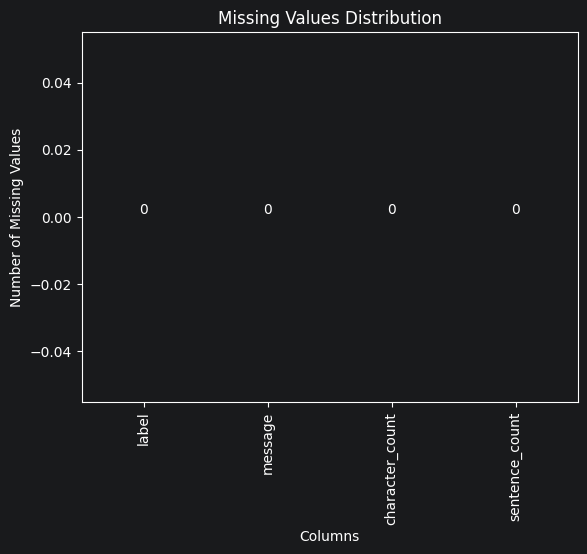

In [6]:
# Count the missing values for each column
missing_values = dataset.isnull().sum()
missing_values = missing_values.plot(kind="bar")

# Add details to the plot
plt.title("Missing Values Distribution")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")

# Add value labels on top of each bar
for bar in missing_values.patches:
    missing_values.annotate(
        str(bar.get_height()),
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom"
    )

# Display the plot
plt.show()

### 2.4 Correlation matrix

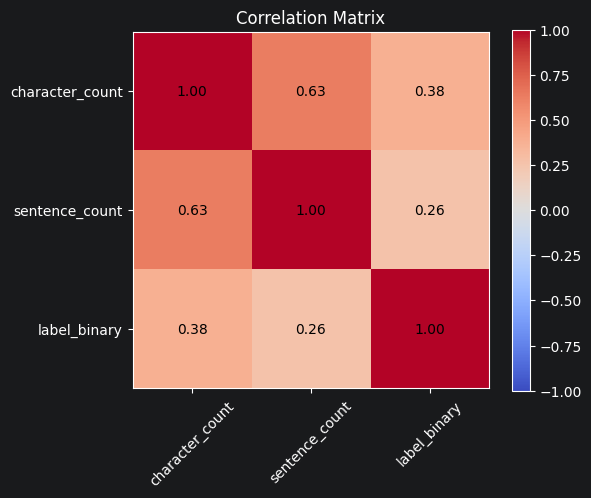

In [7]:
# First convert target variable to binary (so that correlation can be shown)
dataset["label_binary"] = dataset["label"].map({"ham": 0, "spam": 1})

# Select the numerical values and the target variable
numeric_data = dataset[["character_count", "sentence_count", "label_binary"]]

# Compute the correlation matrix
correlation_matrix = numeric_data.corr()

# Plot the matrix
plt.figure(figsize=(6,5))
plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(correlation_matrix.columns)), correlation_matrix.columns, rotation=45)
plt.yticks(range(len(correlation_matrix.columns)),  correlation_matrix.columns)
plt.title("Correlation Matrix")
plt.colorbar()

# Add correlation values inside cells
for i in range(len(correlation_matrix)):
    for j in range(len(correlation_matrix)):
        plt.text(j, i,
                 f"{correlation_matrix.iloc[i, j]:.2f}",
                 ha="center",
                 va="center",
                 color="black")

# Display the plot
plt.tight_layout()
plt.show()

## Task 3: Data Preprocessing

### 3.1 Label Encoding

During the EDA process, we have already performed label encoding, so we'll just drop the original label and rename the binary label.

In [8]:
# First, gain an overview of the dataset
print("Original dataset:")
print(dataset.head())

# Remove the original label and replace with the binary labels
dataset = dataset.drop(columns=["label"])
dataset = dataset.rename(columns={"label_binary": "label"})

# Review the updated dataset
print("\nUpdated dataset:")
print(dataset.head())

Original dataset:
  label                                            message  character_count  sentence_count  label_binary
0   ham  Go until jurong point, crazy.. Available only ...              111               2             0
1   ham                      Ok lar... Joking wif u oni...               29               2             0
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...              155               2             1
3   ham  U dun say so early hor... U c already then say...               49               1             0
4   ham  Nah I don't think he goes to usf, he lives aro...               61               1             0

Updated dataset:
                                             message  character_count  sentence_count  label
0  Go until jurong point, crazy.. Available only ...              111               2      0
1                      Ok lar... Joking wif u oni...               29               2      0
2  Free entry in 2 a wkly comp to win FA Cup fina

### 3.2 Text Cleaning

Texts are converted into lowercase, and unrelevant information (e.g., punctuations, numbers, URLs, email addresses) will be removed.

In [9]:
# Use regex to clean text
def clean_text(text):
    text = text.lower()                                                 # Convert to lowercase
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)                 # Remove URLs
    text = re.sub(r"\S+@\S+", "", text)                                 # Remove email addresses
    text = re.sub(r"\d+", "", text)                                     # Remove numbers
    text = re.sub(r"(.)\1{2,}", r"\1\1", text)                          # Remove elongated words
    text = text.translate(str.maketrans("", "", string.punctuation))    # Remove punctuation
    text = re.sub(r"\s+", " ", text).strip()                            # Remove extra whitespaces
    return text

# Apply cleaning to the message column
dataset["message"] = dataset["message"].apply(clean_text)

# Preview cleaned dataset
print(dataset.head())

                                             message  character_count  sentence_count  label
0  go until jurong point crazy available only in ...              111               2      0
1                            ok lar joking wif u oni               29               2      0
2  free entry in a wkly comp to win fa cup final ...              155               2      1
3        u dun say so early hor u c already then say               49               1      0
4  nah i dont think he goes to usf he lives aroun...               61               1      0


### 3.3 Tokenization and Stop Words Removal

Tokenization is performed to split text into individual tokens so that vectorization can take place, and stop words are removed to reduce noise in the data.

In [10]:
# Retrieve the English stop words from NLTK's corpus
stop_words = set(stopwords.words("english"))

# A function to perform tokenization and stop word removal in one shot
def tokenize_and_remove_stopwords(text):
    tokens = word_tokenize(text)                                            # Perform tokenization
    clean_tokens = [word for word in tokens if word not in stop_words]      # Remove stop words if it exists in NLTK's stopword corpus
    return clean_tokens

# Apply to message column
dataset["tokens"] = dataset["message"].apply(tokenize_and_remove_stopwords)

# Preview results
print(dataset.head())

                                             message  character_count  sentence_count  label                                             tokens
0  go until jurong point crazy available only in ...              111               2      0  [go, jurong, point, crazy, available, bugis, n...
1                            ok lar joking wif u oni               29               2      0                     [ok, lar, joking, wif, u, oni]
2  free entry in a wkly comp to win fa cup final ...              155               2      1  [free, entry, wkly, comp, win, fa, cup, final,...
3        u dun say so early hor u c already then say               49               1      0      [u, dun, say, early, hor, u, c, already, say]
4  nah i dont think he goes to usf he lives aroun...               61               1      0  [nah, dont, think, goes, usf, lives, around, t...


### 3.4 POS Tagging and Lemmatization

Once the noise is removed, lemmatization can be performed to standardize tokens into their base forms to make everything consistent.
POS tagging is performed before lemmatization to provide the grammatical context of the tokens and gives better results.

In [11]:
# Create a lemmatizer object
lemmatizer = WordNetLemmatizer()

# A function to convert tags from POS tagging to tags used by WordNetLemmatizer
def get_wordnet_pos(tag):
    if tag.startswith('J'):     return wordnet.ADJ
    elif tag.startswith('V'):   return wordnet.VERB
    elif tag.startswith('N'):   return wordnet.NOUN
    elif tag.startswith('R'):   return wordnet.ADV
    else:                       return wordnet.NOUN

# The function to return the lemmatized tokens
def lemmatize_with_pos(tokens):
    tagged = nltk.pos_tag(tokens)
    return [
        lemmatizer.lemmatize(word, get_wordnet_pos(tag)) for word, tag in tagged
    ]

# Perform lemmatizations (with POS tagging) on the dataset
dataset["lemmatized_tokens"] = dataset["tokens"].apply(lemmatize_with_pos)

# Display results
print(dataset[["tokens", "lemmatized_tokens"]].head())

                                              tokens                                  lemmatized_tokens
0  [go, jurong, point, crazy, available, bugis, n...  [go, jurong, point, crazy, available, bugis, n...
1                     [ok, lar, joking, wif, u, oni]                     [ok, lar, joking, wif, u, oni]
2  [free, entry, wkly, comp, win, fa, cup, final,...  [free, entry, wkly, comp, win, fa, cup, final,...
3      [u, dun, say, early, hor, u, c, already, say]      [u, dun, say, early, hor, u, c, already, say]
4  [nah, dont, think, goes, usf, lives, around, t...  [nah, dont, think, go, usf, life, around, though]


### 3.5 Train-Test Split

Before performing the remaining preprocessing tasks (TF-IDF and SMOTE), the dataset is split into training and testing in 80:20 ratio to prevent data leakage.

In [12]:
# Divide the attributes into text columns (must combine for TF-IDF), numerical columns and target variable
X_text = dataset["lemmatized_tokens"].apply(lambda x: " ".join(x))
X_num = dataset[["character_count", "sentence_count"]]
y = dataset["label"]

# Perform splitting based on the ratio 80:20
X_text_train, X_text_test, X_num_train, X_num_test, y_train, y_test = train_test_split(
    X_text,
    X_num,
    y,
    test_size=0.2,
    random_state=1029,
    stratify=y
)

# Show the distribution of data after split
print("Training set size:", len(X_text_train))
print("Test set size:", len(X_text_test))

print("\nClass distribution (Train):")
print(y_train.value_counts(normalize=True))     # normalize=True is to show percentage instead of absolute values
print("\nClass distribution (Test):")
print(y_test.value_counts(normalize=True))

Training set size: 4457
Test set size: 1115

Class distribution (Train):
label
0    0.865829
1    0.134171
Name: proportion, dtype: float64

Class distribution (Test):
label
0    0.866368
1    0.133632
Name: proportion, dtype: float64


### 3.6 TF-IDF Vectorization

TF-IDF is performed to convert text data into numerical format so that machine learning algorithms can learn.

In [13]:
# Create a vectorization object with limit set as 5000
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1,2))

# Perform TF-TDF vectorization on training set first, then apply the same transformation on testing set
X_train_tfidf = tfidf.fit_transform(X_text_train)
X_test_tfidf = tfidf.transform(X_text_test)

# Combine the TF-IDF features with numerical attributes
X_train_final = hstack([X_train_tfidf, X_num_train.values])
X_test_final = hstack([X_test_tfidf, X_num_test.values])

# Check the output shape
print("Train shape:", X_train_final.shape)
print("Test shape:", X_test_final.shape)

Train shape: (4457, 5002)
Test shape: (1115, 5002)


### 3.7 Oversampling using SMOTE

The SMOTE technique is applied to balance the target variable in the training set to improve performance and reduce bias.

In [14]:
# Create a SMOTE object
smote = SMOTE(random_state=1029)

# Apply SMOTE on training set
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_final, y_train)

# Compare the class distribution before and after SMOTE
print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_resampled.value_counts())

Before SMOTE:
label
0    3859
1     598
Name: count, dtype: int64

After SMOTE:
label
0    3859
1    3859
Name: count, dtype: int64


## Task 4: Model Building and Evaluation

Four models will be trained: Naive Bayes, SVM, Decision Tree, Logistic Regression.

### 4.1 Naive Bayes

In [49]:
# Create the Naive Bayes model
nb = MultinomialNB()

# Train the model and perform prediction
nb.fit(X_train_resampled, y_train_resampled)
nb_predict = nb.predict(X_test_final)

# Evaluation
print("Baseline Accuracy:", accuracy_score(y_test, nb_predict))
print("Baseline Recall:", recall_score(y_test, nb_predict))
print("Baseline F1-Score:", f1_score(y_test, nb_predict))
print(classification_report(y_test, nb_predict))

# Define the parameters for hyperparameter tuning
nb_params = {
    "alpha": [0.01, 0.1, 0.5, 1.0, 2.0],
    "fit_prior": [True, False]
}

# Use grid search with 10-fold cross-validation to find the best params
nb_grid = GridSearchCV(
    MultinomialNB(),
    param_grid=nb_params,
    cv=10,
    scoring="f1",
    n_jobs=-1
)

# Use the tuned hyperparameter to retrain the model and output the best params and score (on training dataset)
nb_grid.fit(X_train_resampled, y_train_resampled)
print("Best Parameters:", nb_grid.best_params_)
print("Best CV F1-Score:", nb_grid.best_score_)

# Retrieve the best model, run on the testing dataset, and output results
best_nb = nb_grid.best_estimator_
best_nb_predict = best_nb.predict(X_test_final)
print("\nOptimized Test Accuracy:", accuracy_score(y_test, best_nb_predict))
print("Optimized Test Recall:", recall_score(y_test, best_nb_predict))
print("Optimized Test F1-Score:", f1_score(y_test, best_nb_predict))
print(classification_report(y_test, best_nb_predict))

Baseline Accuracy: 0.9533632286995516
Baseline Recall: 0.9664429530201343
Baseline F1-Score: 0.8470588235294118
              precision    recall  f1-score   support

           0       0.99      0.95      0.97       966
           1       0.75      0.97      0.85       149

    accuracy                           0.95      1115
   macro avg       0.87      0.96      0.91      1115
weighted avg       0.96      0.95      0.96      1115

Best Parameters: {'alpha': 0.01, 'fit_prior': True}
Best CV F1-Score: 0.9840755611165879

Optimized Test Accuracy: 0.9623318385650225
Optimized Test Recall: 0.9261744966442953
Optimized Test F1-Score: 0.8679245283018868
              precision    recall  f1-score   support

           0       0.99      0.97      0.98       966
           1       0.82      0.93      0.87       149

    accuracy                           0.96      1115
   macro avg       0.90      0.95      0.92      1115
weighted avg       0.97      0.96      0.96      1115



### 4.2.1 SVM (General Model)

In [53]:
# Create the SVM model
svm = SVC()

# Train the model and perform prediction
svm.fit(X_train_resampled, y_train_resampled)
svm_predict = svm.predict(X_test_final)

# Output baseline metrics
print("Baseline Accuracy:", accuracy_score(y_test, svm_predict))
print("Baseline Recall:", recall_score(y_test, svm_predict))
print("Baseline F1-Score:", f1_score(y_test, svm_predict))
print(classification_report(y_test, svm_predict))

# List down the parameters to be tuned
svm_params = {
    "C": [0.1, 1.0, 10, 100, 500, 1000],
    "kernel": ["linear", "rbf", "poly"],
    "gamma": ["scale", "auto"]
}

# Perform hyperparameter tuning using Grid Search
svm_grid = GridSearchCV(
    SVC(),
    param_grid=svm_params,
    cv=10,
    scoring="f1",
    n_jobs=-1
)

# Train the SVM on the training dataset and output performance (based on training)
svm_grid.fit(X_train_resampled, y_train_resampled)
print("Best Parameters:", svm_grid.best_params_)
print("Best CV F1-Score:", svm_grid.best_score_)

# Use the best hyperparameter to test on the training set and output the results
best_svm = svm_grid.best_estimator_
best_svm_predict = best_svm.predict(X_test_final)
print("\nOptimized Test Accuracy:", accuracy_score(y_test, best_svm_predict))
print("Optimized Test Recall:", recall_score(y_test, best_svm_predict))
print("Optimized Test F1-Score:", f1_score(y_test, best_svm_predict))
print(classification_report(y_test, best_svm_predict))

Baseline Accuracy: 0.8286995515695067
Baseline Recall: 0.9060402684563759
Baseline F1-Score: 0.5856832971800434
              precision    recall  f1-score   support

           0       0.98      0.82      0.89       966
           1       0.43      0.91      0.59       149

    accuracy                           0.83      1115
   macro avg       0.71      0.86      0.74      1115
weighted avg       0.91      0.83      0.85      1115

Best Parameters: {'C': 1000, 'gamma': 'auto', 'kernel': 'rbf'}
Best CV F1-Score: 0.9949556299025935

Optimized Test Accuracy: 0.9829596412556054
Optimized Test Recall: 0.8926174496644296
Optimized Test F1-Score: 0.9333333333333333
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       966
           1       0.98      0.89      0.93       149

    accuracy                           0.98      1115
   macro avg       0.98      0.94      0.96      1115
weighted avg       0.98      0.98      0.98      1115



### 4.2.2 Linear SVM

In [65]:
# Create the linear SVM model
lin_svm = LinearSVC()

# Train the model and perform prediction
lin_svm.fit(X_train_resampled, y_train_resampled)
lin_svm_predict = lin_svm.predict(X_test_final)

# Output baseline metrics
print("Baseline Accuracy:", accuracy_score(y_test, lin_svm_predict))
print("Baseline Recall:", recall_score(y_test, lin_svm_predict))
print("Baseline F1-Score:", f1_score(y_test, lin_svm_predict))
print(classification_report(y_test, lin_svm_predict))

# List down the parameters to be tuned
lin_svm_params = {
    "C": [0.1, 1, 10, 100, 500, 1000, 5000, 10000],
    "loss": ["squared_hinge"]
}

# Perform hyperparameter tuning using Grid Search
lin_svm_grid = GridSearchCV(
    LinearSVC(),
    param_grid=lin_svm_params,
    cv=10,
    scoring="f1",
    n_jobs=-1
)

# Train the linear SVM on the training dataset and output performance (based on training)
lin_svm_grid.fit(X_train_resampled, y_train_resampled)
print("Best Parameters:", lin_svm_grid.best_params_)
print("Best CV F1-Score:", lin_svm_grid.best_score_)

# Use the best hyperparameter to test on the training set and output the results
best_lin_svm = lin_svm_grid.best_estimator_
best_lin_svm_predict = best_lin_svm.predict(X_test_final)
print("\nOptimized Test Accuracy:", accuracy_score(y_test, best_lin_svm_predict))
print("Optimized Test Recall:", recall_score(y_test, best_lin_svm_predict))
print("Optimized Test F1-Score:", f1_score(y_test, best_lin_svm_predict))
print(classification_report(y_test, best_lin_svm_predict))

Baseline Accuracy: 0.9856502242152466
Baseline Recall: 0.912751677852349
Baseline F1-Score: 0.9444444444444444
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       966
           1       0.98      0.91      0.94       149

    accuracy                           0.99      1115
   macro avg       0.98      0.95      0.97      1115
weighted avg       0.99      0.99      0.99      1115

Best Parameters: {'C': 5000, 'loss': 'squared_hinge'}
Best CV F1-Score: 0.9954897863486367

Optimized Test Accuracy: 0.9856502242152466
Optimized Test Recall: 0.9194630872483222
Optimized Test F1-Score: 0.9448275862068966
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       966
           1       0.97      0.92      0.94       149

    accuracy                           0.99      1115
   macro avg       0.98      0.96      0.97      1115
weighted avg       0.99      0.99      0.99      1115



### 4.3 Decision Tree

In [50]:
# Initialize the decision tree model
dt = DecisionTreeClassifier(random_state=1029)

# Train model on training dataset and predict model on testing dataset
dt.fit(X_train_resampled, y_train_resampled)
dt_predict = dt.predict(X_test_final)

# Output the baseline performance
print("Baseline Accuracy:", accuracy_score(y_test, dt_predict))
print("Baseline Recall:", recall_score(y_test, dt_predict))
print("Baseline F1-Score:", f1_score(y_test, dt_predict))
print(classification_report(y_test, dt_predict))

# Outline the list of parameters to be tuned
dt_params = {
    'max_depth': [1, 5, 10, 20, 25, 30, 50],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5],
    'criterion': ['gini', 'entropy']
}

# Perform grid search to find for the best hyperparameter
dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=1029),
    param_grid=dt_params,
    cv=10,
    scoring="f1",
    n_jobs=-1
)

# Use the best hyperparameter on the training dataset
dt_grid.fit(X_train_resampled, y_train_resampled)
print("Best Parameters:", dt_grid.best_params_)
print("Best CV F1-Score:", dt_grid.best_score_)

# Implement the best hyperparameter on the testing dataset and output results
best_dt = dt_grid.best_estimator_
best_dt_predict = best_dt.predict(X_test_final)
print("\nOptimized Test Accuracy:", accuracy_score(y_test, best_dt_predict))
print("Optimized Test Recall:", recall_score(y_test, best_dt_predict))
print("Optimized Test F1-Score:", f1_score(y_test, best_dt_predict))
print(classification_report(y_test, best_dt_predict))

Baseline Accuracy: 0.9587443946188341
Baseline Recall: 0.8791946308724832
Baseline F1-Score: 0.8506493506493507
              precision    recall  f1-score   support

           0       0.98      0.97      0.98       966
           1       0.82      0.88      0.85       149

    accuracy                           0.96      1115
   macro avg       0.90      0.93      0.91      1115
weighted avg       0.96      0.96      0.96      1115

Best Parameters: {'criterion': 'gini', 'max_depth': 25, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV F1-Score: 0.9773554368961817

Optimized Test Accuracy: 0.9632286995515695
Optimized Test Recall: 0.87248322147651
Optimized Test F1-Score: 0.8637873754152824
              precision    recall  f1-score   support

           0       0.98      0.98      0.98       966
           1       0.86      0.87      0.86       149

    accuracy                           0.96      1115
   macro avg       0.92      0.92      0.92      1115
weighted avg       0

### 4.4 Logistic Regression

In [51]:
# Initialize the logistic regression model
lr = LogisticRegression(max_iter=2000)

# Train the model using training dataset and run the model on testing dataset
lr.fit(X_train_resampled, y_train_resampled)
lr_predict = lr.predict(X_test_final)

# Output the baseline performance
print("Baseline Accuracy:", accuracy_score(y_test, lr_predict))
print("Baseline Recall:", recall_score(y_test, lr_predict))
print("Baseline F1-Score:", f1_score(y_test, lr_predict))
print(classification_report(y_test, lr_predict))

# Outline the list of hyperparameters to be tuned
lr_params = {
    "C": [0.01, 0.1, 1, 10, 100, 200, 500, 1000],
    "solver": ["newton-cg", "lbfgs", "liblinear"]
}

# Perform hyperparameter tuning using grid search
lr_grid = GridSearchCV(
    LogisticRegression(max_iter=2000),
    param_grid=lr_params,
    cv=10,
    scoring="f1",
    n_jobs=-1
)

# Apply the model on the training dataset and output performance (training)
lr_grid.fit(X_train_resampled, y_train_resampled)
print("Best Parameters:", lr_grid.best_params_)
print("Best CV F1-Score:", lr_grid.best_score_)

# Apply the best hyperparameters on the testing dataset and output results (testing)
best_lr = lr_grid.best_estimator_
best_lr_predict = best_lr.predict(X_test_final)
print("Optimized Test Accuracy:", accuracy_score(y_test, best_lr_predict))
print("Optimized Test Recall:", recall_score(y_test, best_lr_predict))
print("Optimized Test F1-Score:", f1_score(y_test, best_lr_predict))
print(classification_report(y_test, best_lr_predict))

Baseline Accuracy: 0.9721973094170404
Baseline Recall: 0.9261744966442953
Baseline F1-Score: 0.8990228013029316
              precision    recall  f1-score   support

           0       0.99      0.98      0.98       966
           1       0.87      0.93      0.90       149

    accuracy                           0.97      1115
   macro avg       0.93      0.95      0.94      1115
weighted avg       0.97      0.97      0.97      1115

Best Parameters: {'C': 500, 'solver': 'liblinear'}
Best CV F1-Score: 0.9954881427629987
Optimized Test Accuracy: 0.9865470852017937
Optimized Test Recall: 0.9261744966442953
Optimized Test F1-Score: 0.9484536082474226
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       966
           1       0.97      0.93      0.95       149

    accuracy                           0.99      1115
   macro avg       0.98      0.96      0.97      1115
weighted avg       0.99      0.99      0.99      1115



### 4.5 Ensemble Model

An additional ensemble model to combine all models together to yield better performance by learning the strengths of each individual model.

In [69]:
# Recreate models based on the best hyperparameter obtained
best_nb_model = MultinomialNB(
    alpha=nb_grid.best_params_["alpha"]
)
best_svm_model = SVC(
    C=svm_grid.best_params_["C"],
    kernel=svm_grid.best_params_["kernel"],
    gamma=svm_grid.best_params_["gamma"]
)
best_lin_svm_model = LinearSVC(
    C=lin_svm_grid.best_params_["C"],
    loss=lin_svm_grid.best_params_["loss"]
)
best_dt_model = DecisionTreeClassifier(
    max_depth=dt_grid.best_params_["max_depth"],
    min_samples_split=dt_grid.best_params_["min_samples_split"],
    criterion=dt_grid.best_params_["criterion"],
    random_state=1029
)
best_lr_model = LogisticRegression(
    C=lr_grid.best_params_["C"],
    solver=lr_grid.best_params_["solver"],
    max_iter=1000
)

# Create an ensemble model using majority voting
ensemble_model = VotingClassifier(
    estimators=[
        ("nb", best_nb_model),
        ("svm", best_svm_model),
        ("dt", best_dt_model),
        ("lr", best_lr_model),
        ("lin_svm", best_lin_svm_model),
    ],
    voting="hard"
)

# Train the ensemble model with training dataset and perform prediction on testing dataset
ensemble_model.fit(X_train_resampled, y_train_resampled)
ensemble_predict = ensemble_model.predict(X_test_final)

# Output the accuracy, recall and F1-score of the model
print("Ensemble Model Accuracy:", accuracy_score(y_test, ensemble_predict))
print("Ensemble Model Recall:", recall_score(y_test, ensemble_predict))
print("Ensemble Model F1-Score:", f1_score(y_test, ensemble_predict))
print("\n", classification_report(y_test, ensemble_predict))

Ensemble Model Accuracy: 0.9901345291479821
Ensemble Model Recall: 0.9261744966442953
Ensemble Model F1-Score: 0.9616724738675958

               precision    recall  f1-score   support

           0       0.99      1.00      0.99       966
           1       1.00      0.93      0.96       149

    accuracy                           0.99      1115
   macro avg       0.99      0.96      0.98      1115
weighted avg       0.99      0.99      0.99      1115

